<a href="https://colab.research.google.com/github/mjunaiduiux/Analysis-of-the-Global-Terrorism-Database/blob/main/GTD_Visualization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Data Visualization Mid-Term: Question 1
## Global Terrorism Database (GTD) analysis

**Setup**
- Download the GTD from Kaggle (`START-UMD/gtd`, file `globalterrorismdb_0718dist.csv`).
- Colab: the first data cell asks you to upload the CSV. VS Code: put the CSV next to this notebook.
- Natural Earth 110m cultural data (countries) is downloaded automatically in the choropleth cell.

In [ ]:
%pip install -q geopandas pyogrio scipy seaborn

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd
from matplotlib.colors import LogNorm
from scipy.ndimage import gaussian_filter

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

## 1. Load data and preprocess

In [ ]:
CSV_PATH = "globalterrorismdb_0718dist.csv"

# Colab: upload the file if it is not already there
if not os.path.exists(CSV_PATH):
    try:
        from google.colab import files
        uploaded = files.upload()
        CSV_PATH = list(uploaded.keys())[0]
    except ImportError:
        raise FileNotFoundError(f"Put {CSV_PATH} next to this notebook or change CSV_PATH.")

cols = ["iyear", "country_txt", "region_txt", "attacktype1_txt",
        "targtype1_txt", "nkill", "nwound", "latitude", "longitude"]
df = pd.read_csv(CSV_PATH, encoding="ISO-8859-1", usecols=cols, low_memory=False)
print(df.shape)
df.isna().sum()

(7316, 9)


,0
iyear,0
country_txt,0
region_txt,0
latitude,183
longitude,183
attacktype1_txt,0
targtype1_txt,0
nkill,809
nwound,2043


In [ ]:
# Task: fill missing nkill / nwound with 0
print("Missing before:", df[["nkill", "nwound"]].isna().sum().to_dict())
df[["nkill", "nwound"]] = df[["nkill", "nwound"]].fillna(0)
print("Missing after: ", df[["nkill", "nwound"]].isna().sum().to_dict())

# Casualties = killed + wounded (used in several plots below)
df["casualties"] = df["nkill"] + df["nwound"]
df.head()

Missing before: {'nkill': 809, 'nwound': 2043}
Missing after:  {'nkill': 0, 'nwound': 0}


,iyear,country_txt,region_txt,latitude,longitude,attacktype1_txt,targtype1_txt,nkill,nwound,casualties
0,1970,Dominican Republic,Central America & Caribbean,18.456792,-69.951164,Assassination,Private Citizens & Property,1.0,0.0,1.0
1,1970,Mexico,North America,19.371887,-99.086624,Hostage Taking (Kidnapping),Government (Diplomatic),0.0,0.0,0.0
2,1970,Philippines,Southeast Asia,15.478598,120.599741,Assassination,Journalists & Media,1.0,0.0,1.0
3,1970,Greece,Western Europe,37.997490,23.762728,Bombing/Explosion,Government (Diplomatic),0.0,0.0,0.0
4,1970,Japan,East Asia,33.580412,130.396361,Facility/Infrastructure Attack,Government (Diplomatic),0.0,0.0,0.0


## 2. Bar chart: incidents by country
There are ~200 countries, so the top 20 are shown to keep it readable.

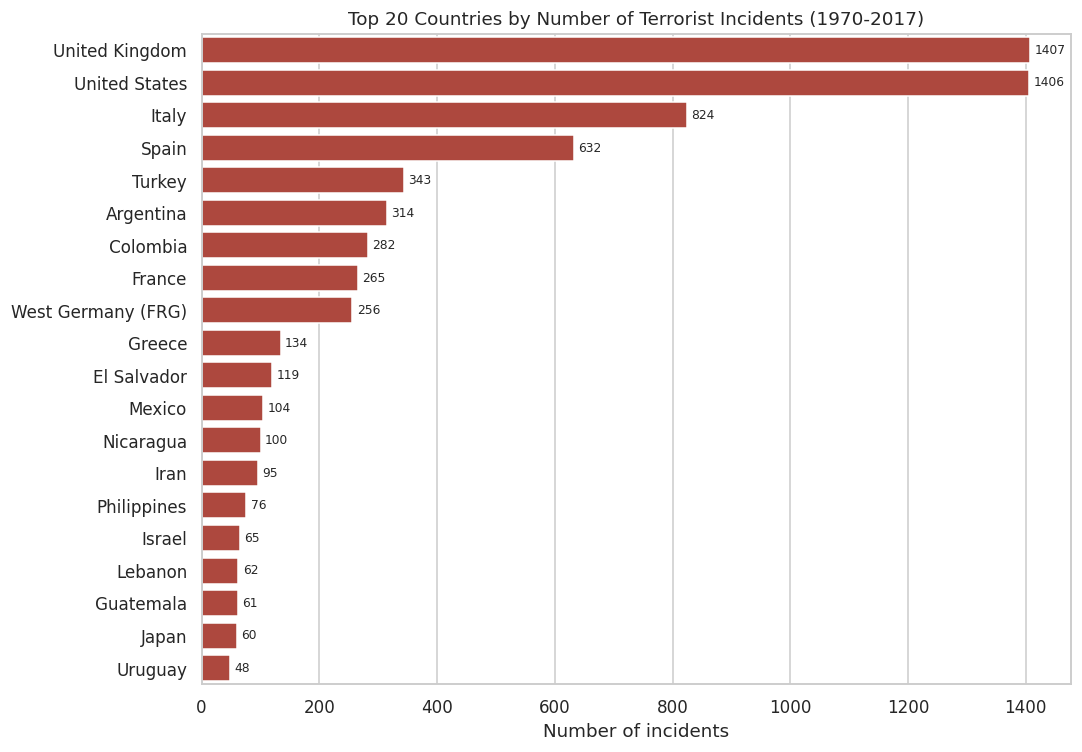

In [ ]:
top_countries = df["country_txt"].value_counts().head(20)

fig, ax = plt.subplots(figsize=(10, 7))
sns.barplot(x=top_countries.values, y=top_countries.index, color="#c0392b", ax=ax)
ax.bar_label(ax.containers[0], padding=3, fontsize=8)
ax.set(title="Top 20 Countries by Number of Terrorist Incidents (1970-2017)",
       xlabel="Number of incidents", ylabel="")
plt.tight_layout()
plt.show()

## 3. Scatter plot: casualties vs. attack type
Attack type is categorical, so points are jittered horizontally and the y-axis uses a symmetric-log scale because casualty counts are extremely skewed.

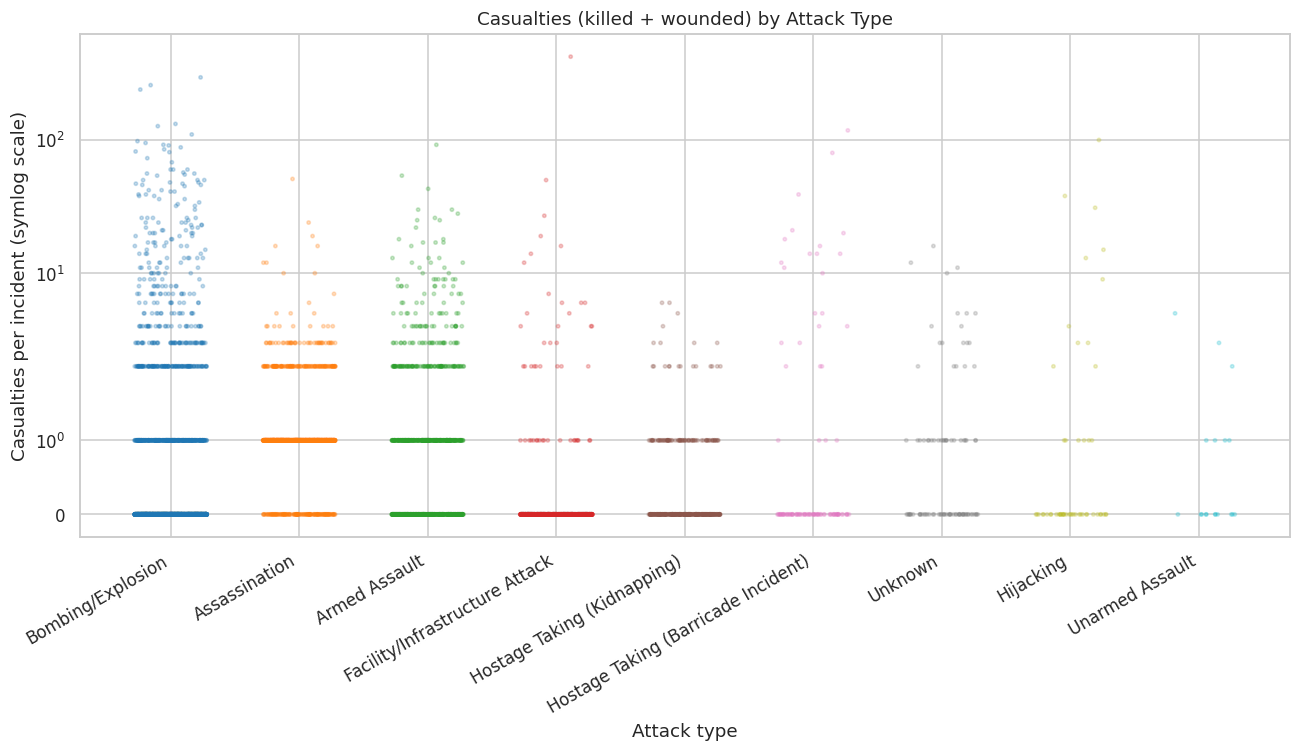

In [ ]:
rng = np.random.default_rng(42)
order = df["attacktype1_txt"].value_counts().index.tolist()
pos = {a: i for i, a in enumerate(order)}
x = df["attacktype1_txt"].map(pos) + rng.uniform(-0.28, 0.28, len(df))

fig, ax = plt.subplots(figsize=(12, 7))
ax.scatter(x, df["casualties"], s=5, alpha=0.25, c=df["attacktype1_txt"].map(pos), cmap="tab10")
ax.set_yscale("symlog")
ax.set_xticks(range(len(order)))
ax.set_xticklabels(order, rotation=30, ha="right")
ax.set(title="Casualties (killed + wounded) by Attack Type",
       xlabel="Attack type", ylabel="Casualties per incident (symlog scale)")
plt.tight_layout()
plt.show()

## 4. Subplots: incidents by year and by attack type

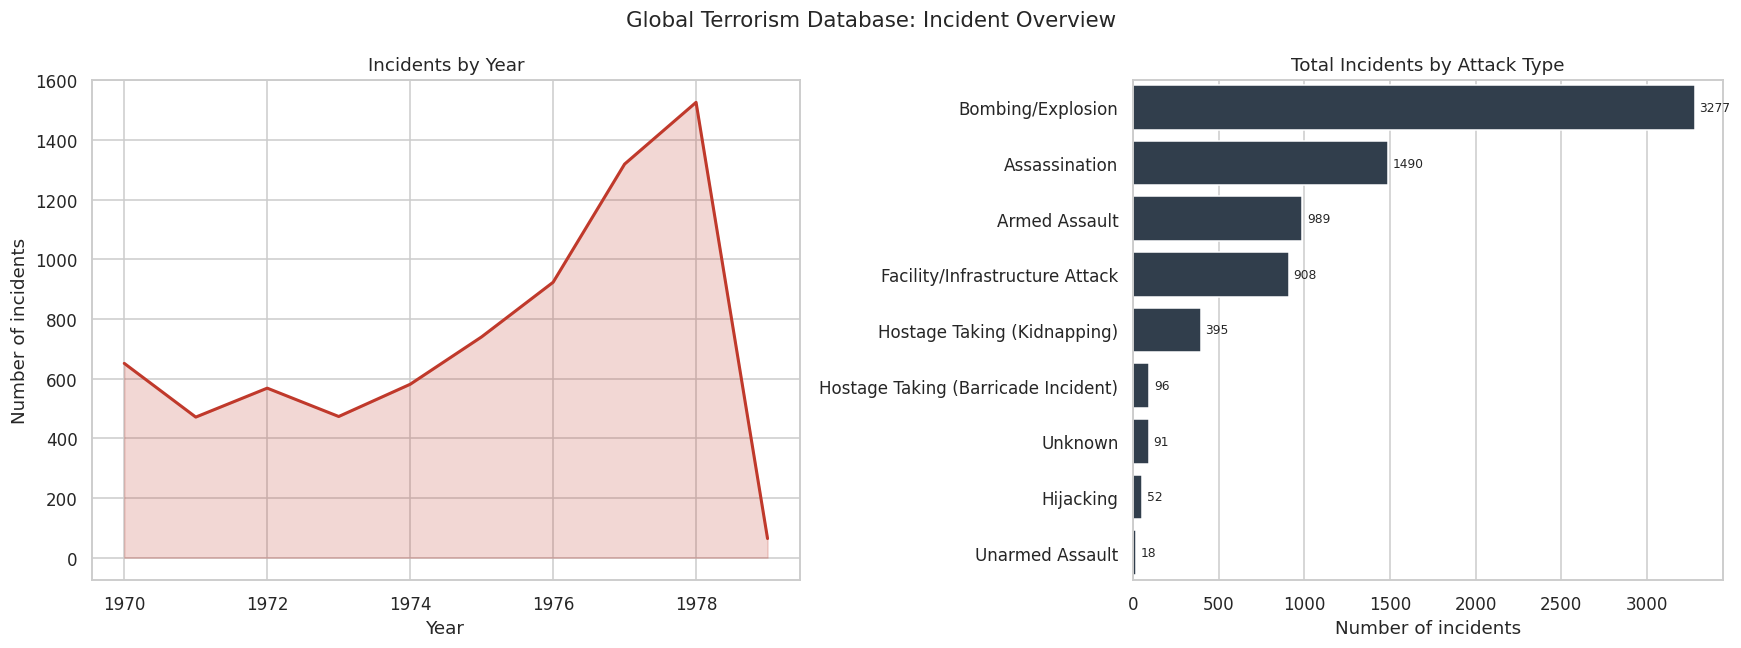

In [ ]:
by_year = df.groupby("iyear").size()
by_attack = df["attacktype1_txt"].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1.2, 1]})

axes[0].plot(by_year.index, by_year.values, color="#c0392b", lw=2)
axes[0].fill_between(by_year.index, by_year.values, alpha=0.2, color="#c0392b")
axes[0].set(title="Incidents by Year", xlabel="Year", ylabel="Number of incidents")

sns.barplot(x=by_attack.values, y=by_attack.index, color="#2c3e50", ax=axes[1])
axes[1].bar_label(axes[1].containers[0], padding=3, fontsize=8)
axes[1].set(title="Total Incidents by Attack Type", xlabel="Number of incidents", ylabel="")

plt.suptitle("Global Terrorism Database: Incident Overview", fontsize=14)
plt.tight_layout()
plt.show()

## 5. Heatmap: attack type by target type
A log colour scale is used so that rare combinations are still visible next to very common ones (empty cells are blank).

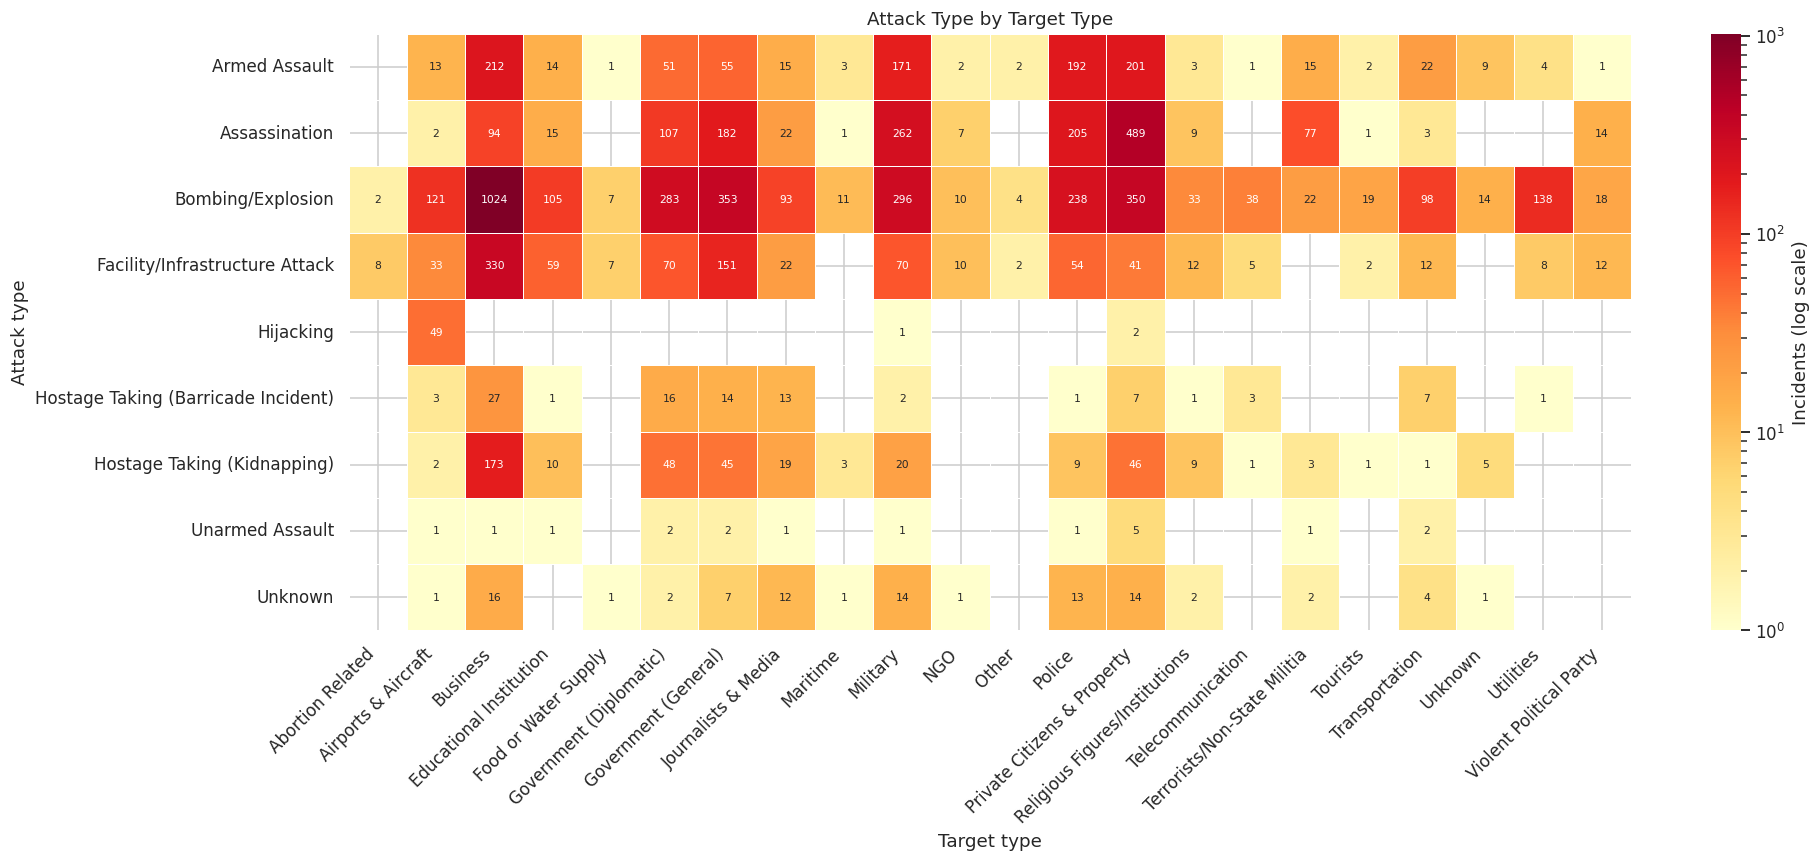

In [ ]:
ct = pd.crosstab(df["attacktype1_txt"], df["targtype1_txt"])

fig, ax = plt.subplots(figsize=(18, 8))
sns.heatmap(ct.where(ct > 0), annot=True, fmt=".0f", annot_kws={"size": 7},
            cmap="YlOrRd", norm=LogNorm(), linewidths=0.4, linecolor="white",
            cbar_kws={"label": "Incidents (log scale)"}, ax=ax)
ax.set(title="Attack Type by Target Type", xlabel="Target type", ylabel="Attack type")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## 6. Choropleth map: incidents by country
Uses Natural Earth **110m cultural vectors** (`ne_110m_admin_0_countries`). If the download fails, get the zip manually from naturalearthdata.com (Downloads > Cultural > 110m > Admin 0 Countries) and set `NE_PATH` to its location.

GTD countries with no match on the 110m map (mostly tiny states / historical): ['Andorra', 'Barbados', 'Czechoslovakia', 'East Germany (GDR)', 'Malta', 'North Yemen', 'Rhodesia', 'Singapore', 'South Vietnam', 'South Yemen', 'Soviet Union', 'West Germany (FRG)', 'Yugoslavia', 'Zaire']


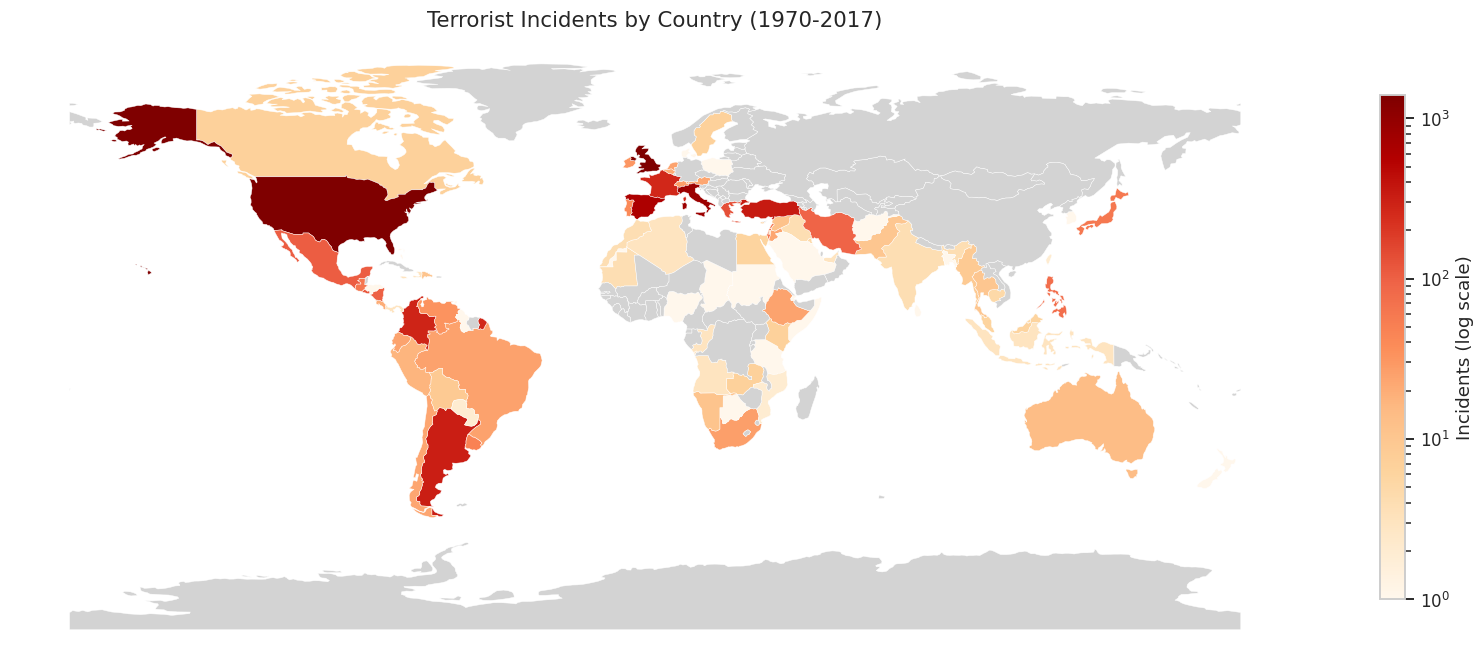

In [ ]:
NE_PATH = "https://naciscdn.org/naturalearth/110m/cultural/ne_110m_admin_0_countries.zip"
world = gpd.read_file(NE_PATH)
world.columns = [c if c == "geometry" else c.upper() for c in world.columns]

# GTD country names -> Natural Earth names
NAME_FIX = {
    "United States": "United States of America",
    "Ivory Coast": "Côte d'Ivoire",
    "Bosnia-Herzegovina": "Bosnia and Herz.",
    "Central African Republic": "Central African Rep.",
    "Democratic Republic of the Congo": "Dem. Rep. Congo",
    "People's Republic of the Congo": "Congo",
    "Republic of the Congo": "Congo",
    "Dominican Republic": "Dominican Rep.",
    "South Sudan": "S. Sudan",
    "Western Sahara": "W. Sahara",
    "Czech Republic": "Czechia",
    "Macedonia": "North Macedonia",
    "Swaziland": "eSwatini",
    "East Timor": "Timor-Leste",
    "Falkland Islands": "Falkland Is.",
    "Equatorial Guinea": "Eq. Guinea",
    "West Bank and Gaza Strip": "Palestine",
    "Solomon Islands": "Solomon Is.",
    "Northern Cyprus": "N. Cyprus",
}

counts = (df["country_txt"].replace(NAME_FIX).value_counts()
          .rename_axis("NAME").reset_index(name="incidents"))
merged = world.merge(counts, on="NAME", how="left")

unmatched = sorted(set(counts["NAME"]) - set(world["NAME"]))
print("GTD countries with no match on the 110m map (mostly tiny states / historical):", unmatched)

fig, ax = plt.subplots(figsize=(15, 8))
merged.plot(column="incidents", cmap="OrRd", norm=LogNorm(vmin=1, vmax=merged["incidents"].max()),
            legend=True, legend_kwds={"label": "Incidents (log scale)", "shrink": 0.6},
            missing_kwds={"color": "lightgrey", "label": "No data"},
            edgecolor="white", linewidth=0.3, ax=ax)
ax.set_title("Terrorist Incidents by Country (1970-2017)", fontsize=14)
ax.set_axis_off()
plt.tight_layout()
plt.show()

## 7. 3D plot: activity by year, region and casualties

/tmp/ipykernel_4795/1296997357.py:19: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


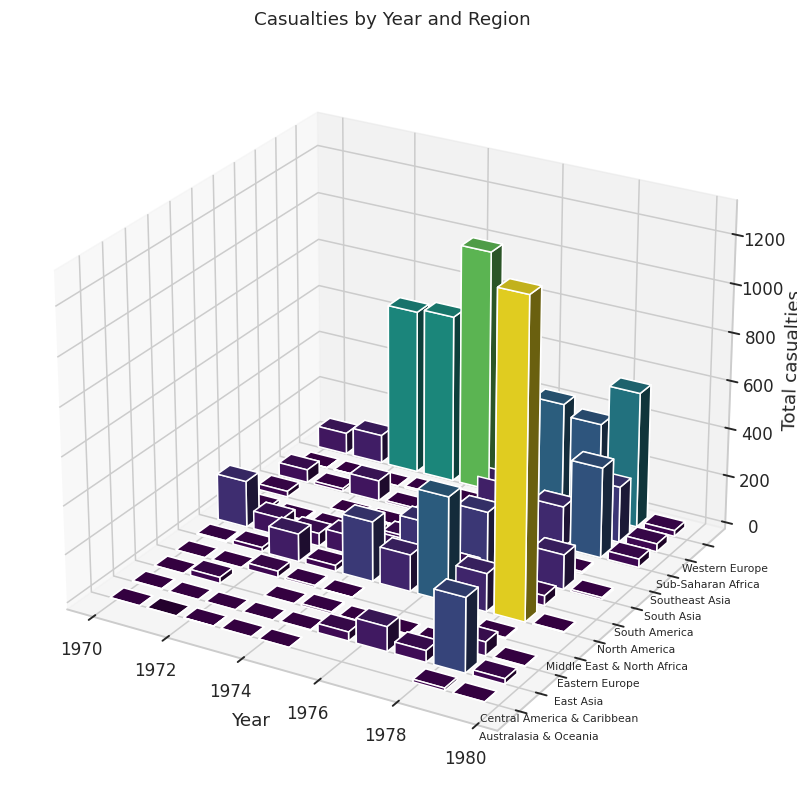

In [ ]:
agg = df.groupby(["iyear", "region_txt"])["casualties"].sum().reset_index()
regions = sorted(agg["region_txt"].unique())
ridx = {r: i for i, r in enumerate(regions)}

xs = agg["iyear"].values
ys = agg["region_txt"].map(ridx).values
zs = agg["casualties"].values

fig = plt.figure(figsize=(14, 9))
ax = fig.add_subplot(111, projection="3d")
colors = plt.cm.viridis(zs / zs.max())
ax.bar3d(xs, ys, np.zeros(len(agg)), 0.8, 0.6, zs, color=colors, shade=True)

ax.set_yticks(np.arange(len(regions)) + 0.3)
ax.set_yticklabels(regions, fontsize=7)
ax.set(xlabel="Year", zlabel="Total casualties", title="Casualties by Year and Region")
ax.set_ylabel("")
ax.view_init(elev=25, azim=-60)
plt.tight_layout()
plt.show()

## 8. Contour plot: casualty density by location
Casualties are binned on a 1-degree lat/lon grid, smoothed with a Gaussian filter, and drawn over the Natural Earth country outlines.

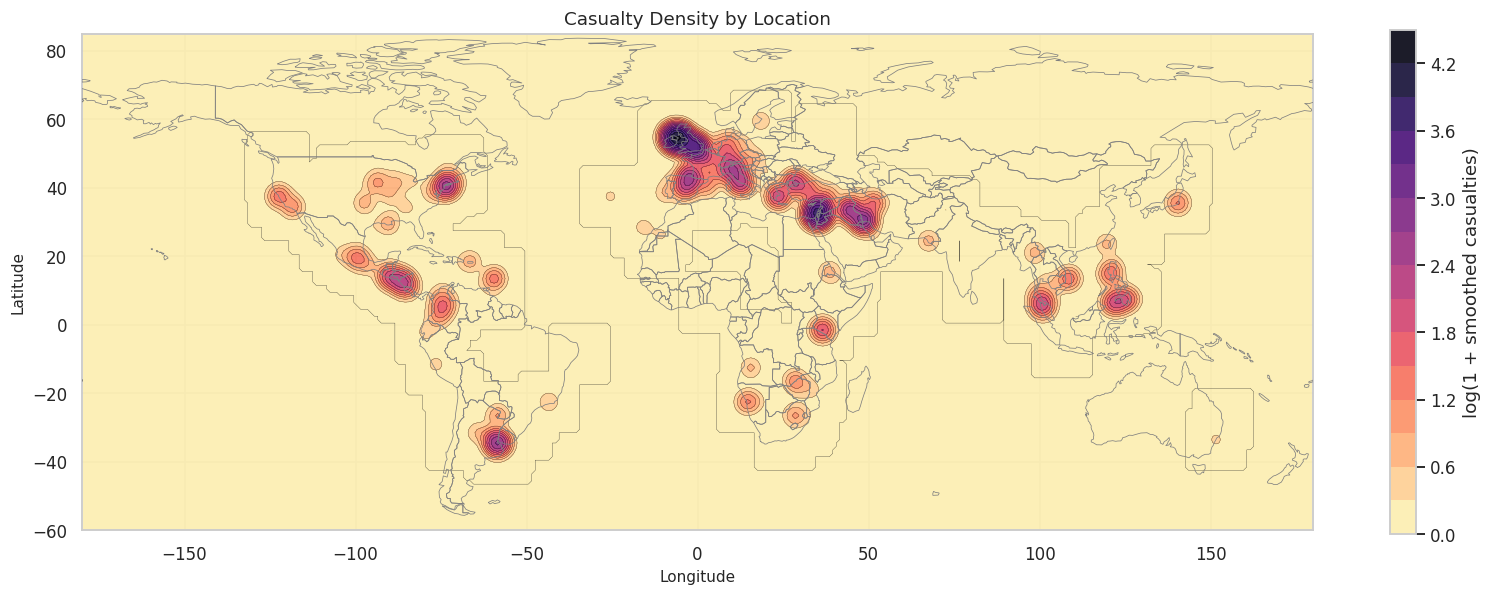

In [ ]:
geo = df.dropna(subset=["latitude", "longitude"])
geo = geo[geo["latitude"].between(-90, 90) & geo["longitude"].between(-180, 180)]

H, xe, ye = np.histogram2d(geo["longitude"], geo["latitude"], bins=[360, 180],
                           range=[[-180, 180], [-90, 90]], weights=geo["casualties"])
H = gaussian_filter(H, sigma=2)
Z = np.log1p(H.T)                      # log scale: a few hotspots dominate otherwise
xc = (xe[:-1] + xe[1:]) / 2
yc = (ye[:-1] + ye[1:]) / 2

fig, ax = plt.subplots(figsize=(15, 8))
cf = ax.contourf(xc, yc, Z, levels=15, cmap="magma_r", alpha=0.9)
ax.contour(xc, yc, Z, levels=15, colors="k", linewidths=0.2)
world.boundary.plot(ax=ax, color="grey", linewidth=0.5, zorder=3)
fig.colorbar(cf, ax=ax, shrink=0.6, label="log(1 + smoothed casualties)")
ax.set(title="Casualty Density by Location", xlabel="Longitude", ylabel="Latitude",
       xlim=(-180, 180), ylim=(-60, 85))
plt.tight_layout()
plt.show()